**Problem Statement and Research Question:**

We will conduct a statistical analysis to differentiate writing styles of Supreme Court justices and determine authorship of Court decisions, using a panel of stylistic metrics that we will calculate from raw textual data (e.g., sentence/word length, punctuation usage). We are especially interested in applying our model to unsigned, per curiam decisions—determining which justices may have played a stronger role in shaping these decisions can change how we understand the legal precedents that they create. Therefore, our finalized research question is: do Supreme Court justices have distinct, measurable writing styles that can be reliably identified using textual features?

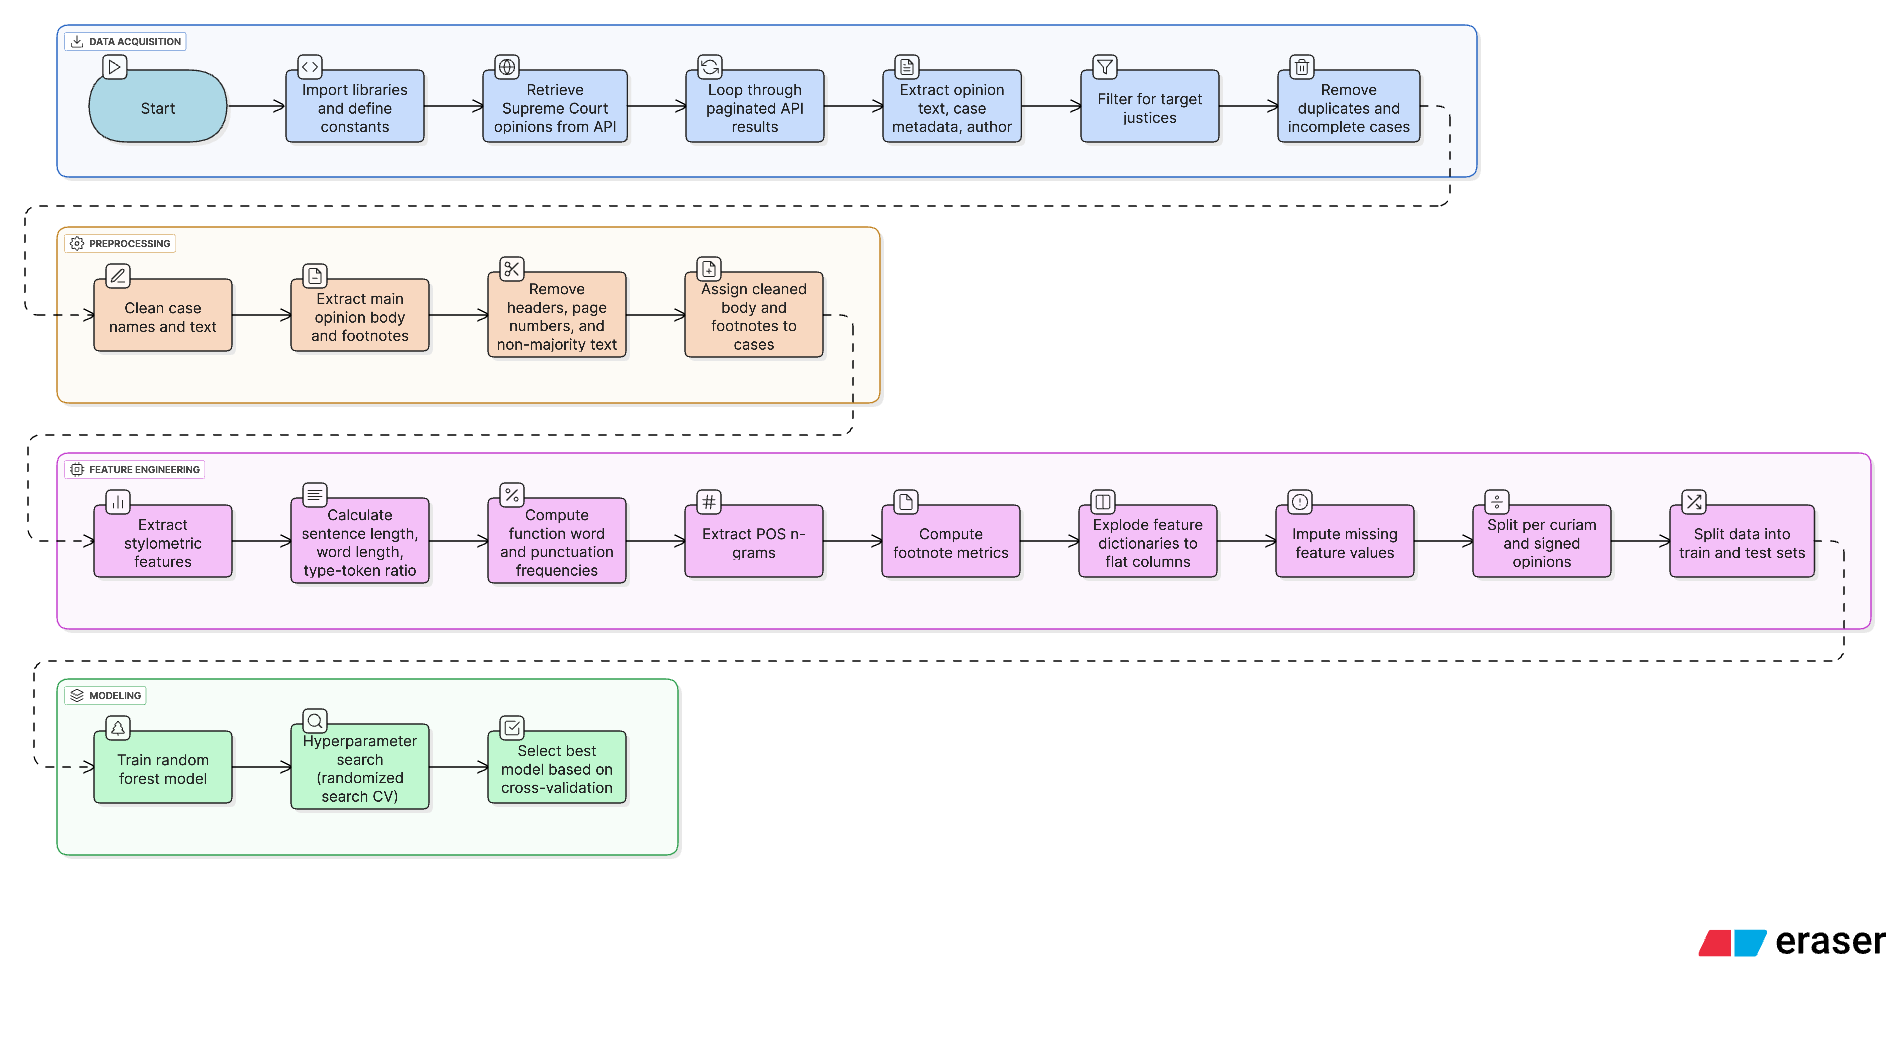


# **Table of contents**


- [Part 0: Setup](#part-0-setup)
- [Part 1: Opinion Text Retrieval](#part-1-opinion-text-retrieval)
- [Part 2: Pre-processing](#part-2-pre-processing)
- [Part 3: Load Data & Summary Statistics](#part-3-load-data-summary-statistics)
- [Part 4: Feature Extraction](#part-4-feature-extraction)
- [Part 5: Feature EDA](#part-5-feature-eda)
- [Part 6: Model Creation](#part-6-model-creation)
  - [Naive Model: Majority Class](#naive-model-majority-class)
  - [Baseline Model: Logistic Regression](#baseline-model-logistic-regression)
  - [Advanced Model 1: One Decision Tree](#advanced-model-1-one-decision-tree)
  - [Advanced Model 2: Random Forest](#advanced-model-2-random-forest)
  - [Advanced Model 3: AdaBoost](#advanced-model-3-adaboost)
- [Part 7: Model Selection](#part-7-model-selection)
- [Part 8: Model Performance](#part-8-model-performance)
  - [Feature Importance](#feature-importance)
  - [Confusion Matrix](#confusion-matrix)
- [Part 9: Application to a Per Curiam Case](#part-9-application-to-a-per-curiam-case)


# **Part 0: Setup**

**Step 1:** Import libraries.

We use ```google.colab```, ```os```, ```requests```, ```json```, ```csv```, and re in order to access and save our data; ```numpy``` and ```pandas``` to manipulate datasets; ```nltk``` and ```collections``` to parse the opinion text and tags words so that we may create additional features; ```matplot``` and ```seaborn``` for visualizations; and ```sklearn``` for model creation, testing, and selection.

In [ ]:
from google.colab import drive
import os

import requests
import json
import csv
import re

import numpy as np
import pandas as pd

from collections import Counter
import nltk
from nltk import word_tokenize, pos_tag, ngrams
nltk.download('all', quiet=True)

import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.model_selection import (cross_val_score, train_test_split,
                                    GridSearchCV, RandomizedSearchCV)

**Step 2:** Change working directory and mount drive.

In [ ]:
drive.mount('/content/drive', force_remount = True)
os.chdir('/content/drive/MyDrive/cs1090a_project/content')


Mounted at /content/drive


# **Part 1: Opinion Text Retrieval**

**Step 1:** Define constants, knobs, and paths for retrieval.

In [ ]:
TOKEN = os.environ["COURTLISTENER_TOKEN"]
BASE_URL = "https://www.courtlistener.com/api/rest/v4"

TARGET_JUSTICES = [
    "Clarence Thomas",
    "Elena Kagan",
    "Brett M. Kavanaugh",
    "Sonia Sotomayor",
    "John Glover Roberts",
    "Amy Coney Barrett",
    "Samuel A. Alito",
    "Ketanji Brown Jackson",
    "Neil McGill Gorsuch",
    "Per Curiam"
]

OUT_FOLDER = 'cases'
TARGETS = ['plain_text', 'cluster', 'author']
START_YEAR = 2021
END_YEAR = 2025

HEADERS = {
  'Authorization': f'Token {TOKEN}',
  'Accept': 'application/json'
}

PARAMS = {
  'cluster__docket__court': 'scotus',
  'order_by': 'id',
  'fields': (",").join(TARGETS),
  'cluster__date_filed__gte': f'{START_YEAR}-01-01',
  'cluster__date_filed__lte': f'{END_YEAR}-12-31',
}

ABRIDGED_FINAL = True

REQUEST_URL = f"{BASE_URL}/opinions"

**Step 2:** Define helper functions to get a justice's name from the URL, extract information from a cluster (case), and clean a case's name.

In [ ]:
def get_author_name(author_url, headers, cache):
  """Get the full name of a justice from their URL (with caching)."""
  if not author_url:
    return "Per Curiam"

  if author_url in cache:
    return cache[author_url]

  try:
    response = requests.get(author_url,
                            headers=headers,
                            params={'fields': 'name_first,name_middle,name_last'})
    response.raise_for_status()
    data = response.json()

    name_parts = []
    if data.get('name_first'):
        name_parts.append(data['name_first'])
    if data.get('name_middle'):
        name_parts.append(data['name_middle'])
    if data.get('name_last'):
        name_parts.append(data['name_last'])

    result = ' '.join(name_parts) if name_parts else "Unknown"
    cache[author_url] = result
    return result
  except:
    cache[author_url] = "Unknown"
    return "Unknown"

def get_info_from_cluster(cluster_url, headers, cache):
  """Get case name and date from cluster URL (with caching)."""
  if not cluster_url:
    return '', ''

  if cluster_url in cache:
    return cache[cluster_url]

  try:
    response = requests.get(cluster_url,
                            headers=headers,
                            params={'fields': 'case_name,date_filed'})
    response.raise_for_status()
    data = response.json()
    case_name = data.get('case_name')
    date_filed = data.get('date_filed')

    # Derive year if date_filed is present and formatted YYYY-MM-DD
    year = None
    if date_filed:
        try:
            year = int(date_filed[:4])
        except ValueError:
            year = ''

    result = (case_name, year)
    cache[cluster_url] = result
    return result
  except:
    cache[cluster_url] = ('', '')
    return '', ''

def clean_case_name(case_name):
    """Remove 'Revisions: M/DD/YY' from case names"""
    # Pattern to match "Revisions: M/DD/YY" or "Revision: M/DD/YY" at the end
    if not case_name:
      return ''

    pattern = r'\s*Revisions?:\s*(\d{1,2}/\d{1,2}/\d{2,4})\s*$'
    match = re.search(pattern, case_name, re.IGNORECASE)

    if match:
        revision_date = match.group(1)
        cleaned_name = re.sub(pattern, '', case_name, flags=re.IGNORECASE).strip()
        return cleaned_name

    return case_name or ''

def recreate_dir(path):
    """Delete all files in a directory if it exists, otherwise create it."""
    if os.path.exists(path):
        for filename in os.listdir(path):
            file_path = os.path.join(path, filename)
            if os.path.isfile(file_path):
                os.remove(file_path)
    else:
        os.makedirs(path)

def create_file_name(stem = "default", suffix = ".csv"):
  if START_YEAR == END_YEAR:
    return f'{stem}__{START_YEAR}{suffix}'

  return f'{stem}__{START_YEAR}_{END_YEAR}{suffix}'

**Step 3:** Create caches for cluster and author mappings; reset output folder.

In [ ]:
cluster_cache = {}
author_cache = {}
recreate_dir(OUT_FOLDER)

**Step 4:** Retrieve all the opinions within the given date range

In [ ]:
page_num = 0
url = REQUEST_URL
opinion_objects = []

while url:
  page_num += 1
  if page_num == 1:
      response = requests.get(url, headers=HEADERS, params=PARAMS)
  else:
      response = requests.get(url, headers=HEADERS)

  response.raise_for_status()
  data = response.json()
  opinions = data.get('results', [])
  opinion_objects.extend(opinions)
  url = data.get('next')

print(f"\n✓ Fetched {len(opinion_objects)} total opinions from CourtListener")


✓ Fetched 755 total opinions from CourtListener


**Step 5:** Retrieve data about the cases (e.g., ```full_text```, ```case name```, ```decision```, ```author```, ```year```)

In [ ]:
errors = []
cases = pd.DataFrame(columns=['case_name', 'author', 'year', 'plain_text', 'body', 'footnotes'])
for idx, opinion_object in enumerate(opinion_objects, 1):
  plain_text, cluster, author = (opinion_object.get(k, '') for k in TARGETS)
  case_name, year = get_info_from_cluster(cluster, HEADERS, cluster_cache)
  author = get_author_name(author, HEADERS, author_cache)

  if not case_name:
    errors.append(f"Did not locate case name for opinion number: {idx}")
    continue

  if not plain_text:
    errors.append(f"Did not locate plain text for case: {case_name}")
    continue

  if not author:
    errors.append(f"No author for case: {case_name}")
    continue

  new_case = {
      'case_name': clean_case_name(case_name),
      'author': author,
      'year': year,
      'plain_text': plain_text,
      'body': '',
      'footnotes': ''
  }

  # Append new case onto results dataframe
  cases.loc[len(cases)] = new_case

before = len(cases)
cases = cases.drop_duplicates(subset=["case_name", "author", "year"])
after = len(cases)

print(f"\n\n᳃ Began with {len(opinion_objects)} cases")
# We can do this because it is likely MCAR
print(f"Dropped {len(errors)} cases due to insufficient data (i.e., lack of plain_text, case_name, or author)")
for error in errors:
  print(f"    ERROR: {error}")
print(f"\nDropped {before - after} duplicate cases")
print(f"✓ Finalized case dataframe with {after} total cases")



᳃ Began with 755 cases
Dropped 1 cases due to insufficient data (i.e., lack of plain_text, case_name, or author)
    ERROR: Did not locate case name for opinion number: 113

Dropped 233 duplicate cases
✓ Finalized case dataframe with 521 total cases


# **Part 2: Pre-processing**

**Step 1:** Quickly remove Justices that are not our targets.

In [ ]:
cases = cases[cases["author"].isin(TARGET_JUSTICES)].reset_index(drop=True)

**Step 2:** Define helper function(s).

In [ ]:
def concat_hyphenated(text):
   text = re.sub(r'-\s*\n\s*', '', text)
   return text

def extract_footnotes(body):
  dash_line_re  = re.compile(r'(?m)^[\u2012\u2013\u2014\u2015-]+\s*\d+\s')


  # Find all dashed footnote sections first
  matches = list(dash_line_re.finditer(body))
  footnote_blocks = []

  for m in reversed(matches):
      start = m.start()

      # Find end of the block (two blank lines not following a hyphen)
      tail = body[start:]
      end_match = re.search(r'(?s)(?<!-)\n[ \t]*\n[ \t]*\n', tail)
      end = start + end_match.start() if end_match else len(body)

      block = body[start:end]
      footnote_blocks.append(block)
      body = body[:start] + "\n\n" + body[end:]

  # Combine and clean
  combined_fn_text = "\n".join(reversed(footnote_blocks))
  combined_fn_text = re.sub(r'(?m)^[\u2012\u2013\u2014\u2015-]{3,}\s*$', '', combined_fn_text).strip()

  footnotes = []
  if combined_fn_text:
      pieces = re.split(r'(?m)(?=^ {3}\d+ )', combined_fn_text)

      for piece in pieces:
          piece = piece.strip()
          if not piece:
              continue

          text = concat_hyphenated(piece)
          text = text[2:]
          text = re.sub(r'\s*\n\s*', ' ', text).strip()

          footnotes.append(text)

  return body.strip(), footnotes

**Step 3:** Define main process function to retrieve body and footnotes from ```plain_text```.

In [ ]:
def process(plain_text, case_name):
  is_per_curiam = "PER CURIAM." in plain_text

  # Step 0: Get only the text of majority opinion; ignore the syllabus & other
  # text that precedes, and concurring / dissenting opinions that may follow
  if is_per_curiam:
      match = re.search(
          r"(?s)PER\s+CURIAM\.\s*(.*?)\s*(?:It\s+is\s+so\s+ordered\.)",
          plain_text
      )
      if not match:
          return "", []
      body = match.group(1).strip()

  else:
      pattern = (
          r"(?s)"
          r"(?:CHIEF\s+)?JUSTICE\s+[A-Z][A-Za-z]+"       # "JUSTICE X" or "CHIEF JUSTICE X"
          r"(?:,\s+with.*?)*?"                           # optional joined justices
          r"\s+delivered\s+the\s+opinion"                # "delivered the opinion"
          r"(?:\s+(?:of|for)\s+the\s+Court)?\."          # optional "of/for the Court."
          r"(.*?)"                                       # capture the opinion body
          r"(?:It\s+is\s+so\s+ordered\.)"                # stop before this phrase
      )

      match = re.search(pattern, plain_text)
      if not match:
          return "", []

      body = match.group(1).strip()

  # Step 1: Extract footnotes
  body, footnotes = extract_footnotes(body)

  # Step 2: Get rid of the headers
  if is_per_curiam:
    body = re.sub(
        r"(?mi)"
        r"^(?:"
        r"\s*Per\s+Curiam\.?\s*$|"                                     # standalone "Per Curiam" or "Per Curiam."
        r"\s*Cite\s+as:.*$|"                                           # "Cite as: 604 U. S. ____ (2025)"
        r"\s*SUPREME\s+COURT\s+OF\s+THE\s+UNITED\s+STATES.*$|"         # title page
        r"^\s*\d{1,3}\s+[A-Z][A-Z .,'&;:()\-]+v\.[A-Z .,'&;:()\-]+$|"  # case title header
        r"^\s*\f\s*$"                                                  # form-feed/page marker
        r")",
        "",
        body,
    )
  else:
    body = re.sub(
        r"(?m)"  # multiline mode
        r"^(?:"
        r"\s*Cite\s+as:.*$|"                                    # "Cite as: 604 U. S. ____ (2025)"
        r"\s*SUPREME\s+COURT\s+OF\s+THE\s+UNITED\s+STATES.*$|"  # title page
        r"\s*Opinion\s+of\s+the\s+Court\s*$|"                   # section header
        r"^\s*—+\s*$|"                                          # any separator line of dashes
        r"^\s*\f\s*$"                                           # page form-feed markers
        r")",
        "",
        body,
    )

  # Step 3: Get rid of the page numbers that include the cases's name
  body = re.sub(
    r"(?m)^\s*\d{1,3}\s+[A-Z][A-Z .,'&;:()\-]+v\.[A-Z .,'&;:()\-]+$",
    "",
    body,
  )

  return body if body else "", footnotes if footnotes else []

**Step 4:** For each case, fill in `body` and `footnotes` fields from our pre-processing function.

In [ ]:
cases[["body", "footnotes"]] = cases.apply(
    lambda row: pd.Series(process(row["plain_text"], row["case_name"])),
    axis=1
)

cases['body'] = cases['body'].replace(r'^\s*$', np.nan, regex=True)
cases = cases.dropna(subset=['body']).copy()

print(f"✓ Found {len(cases)} total majority opinions and successfully preprocessed them")


✓ Found 268 total majority opinions and successfully preprocessed them


**Step 5:** Create or clear output folder; save results in a `.json` for easy display.

In [ ]:
# If we set the ABRIDGED_FINAL knob (for debugging purposes, not to be used for model creation)
if ABRIDGED_FINAL:
  cases_copy = cases.copy()
  cases_copy["plain_text"] = cases_copy["plain_text"].str[:50]
  cases_copy["body"] = cases_copy["body"].str[:50]
  cases_copy["footnotes"] = cases_copy["footnotes"].apply(
      lambda x: [s[:50] for s in x] if isinstance(x, list) else None
  )

  cases_copy.to_json(
    OUT_FOLDER + "/" + create_file_name("opinions_abridged_df", ".json"),
    orient="records",
    indent=2,
    force_ascii=False
  )

cases.to_json(
    OUT_FOLDER + "/" + create_file_name("opinions_df", ".json"),
    orient="records",
    indent=2,
    force_ascii=False
)

# **Part 3: Load Data & Summary Statistics**

**Step 1:** Define paths, constants, and knobs.

In [ ]:
IN_FOLDER = 'cases'
IN_FILE = 'opinions_df__2021_2025.json'

**Step 2:** Load the case data we just saved.

In [ ]:
cases_feat = pd.read_json(IN_FOLDER + '/' + IN_FILE)

In [ ]:
summary_statistics = {
  "Shape":            cases_feat.shape,
  "num_missing":      cases_feat.isna().sum(),
  "Cases by author":  cases_feat["author"].value_counts(),
  "Cases by year":    cases_feat["year"].value_counts()
}

for key, value in summary_statistics.items():
  print(f"{key}:")
  display(value)
  print("\n\n")

Shape:


(268, 6)




num_missing:


,0
case_name,0
author,0
year,0
plain_text,0
body,0
footnotes,0





Cases by author:


,count
author,
Per Curiam,42
Clarence Thomas,31
Brett M. Kavanaugh,30
Elena Kagan,30
John Glover Roberts,28
Sonia Sotomayor,28
Amy Coney Barrett,27
Samuel A. Alito,26
Ketanji Brown Jackson,15





Cases by year:


,count
year,
2025,63
2024,58
2023,51
2022,49
2021,47


We count 226 cases in the relevant time span, with most justices having authored about 30 opinions each.

Although we are able to create a large number of specific features from each opinion (more on this process in the following section), this total is lower than we would like.  Certain constraints mean that naively increasing the number of opinions considered is not so simple (recall that Ketanji Brown Jackson joined the court only in 2022).  We may seek to implement a method that will allow us to incorporate data from older opinions (after all, Clarence Thomas has served on the court for over thirty years).  We will continue to evaluate our options as we train our initial models. We are most interested in the body and footnotes fields, both of which are created from the ```plain_text```.  We then run a series of independent feature extraction functions on each case in the data in order to provide us with tractable quantitative input for our model.


# **Part 4: Feature Extraction**



Our features consist of many stylometric features such as average sentence length, distribution of function words, etc. These measures are commonly used as indicators of authorship. Current literature also suggests that capturing deeper grammatical patterns can help distinguish between authors, so we applied Python’s NLTK’s part-of-speech (POS) tagger to each case to extract general grammatical patterns, including sequences like DT-NN (a determiner followed by a noun). For EDA and for use in our model in the later sections of this notebook, we explode the dictionaries in ```function_words```, ```punc_freq```, ```char_ngrams```, and ```pos_ngrams```.

**Step 1:** Define functions that extract features.

In [ ]:
def avg_sentence_length(text):
  sentences = text.split('. ')

  lengths = []
  for sentence in sentences:
    words = sentence.split(' ')
    lengths.append(len(words))

  return np.mean(lengths)

def avg_word_length(text):
  words = text.split(' ')

  lengths = []
  for word in words:
    lengths.append(len(word))

  return np.mean(lengths)

def type_token_ratio(text):
  words = text.lower().split(' ')
  types = set(words)
  return len(types) / len(words)

def function_words(text):
  function_words = [
    "the", "a", "an", "and", "but", "or", "if", "because", "as", "until", "while",
    "of", "in", "on", "at", "by", "for", "to", "from", "with", "without",
    "he", "she", "it", "they", "we", "i", "you", "me", "him", "her", "them",
    "this", "that", "these", "those",
    "has", "have", "had", "is", "are", "was", "were", "be", "been", "being",
    "do", "does", "did",
    "not", "no", "yes",
    "some", "any", "most", "much", "many", "few"
  ]
  words = text.lower().split(' ')
  total_words = len(words)
  counts = Counter(words)
  func_words = {}
  for word in function_words:
    func_words[f"fw_{word}"] = counts[word] / total_words

  return func_words

def punc_freq(text):
  punctuation = [".", ",", "!", "?", ";", ":", "-", "—", "(", ")", "\"", "'", "…"]
  text = text.lower()
  total_chars = len(text)
  counts = Counter(c for c in text if c in punctuation)
  punc_freqs = {}
  for punc in punctuation:
      punc_freqs[f"punc_{punc}"] = counts[punc] / total_chars

  return punc_freqs

def num_footnotes(text, footnotes):
  words = text.split(' ')
  return (len(footnotes)/len(words))

def avg_footnote_length(footnotes):
  lengths = []
  if not footnotes:
    return 0
  for footnote in footnotes:
    lengths.append(len(footnote))
  return np.mean(lengths)

def pos_ngrams(text):
  n = 2
  tokens = word_tokenize(text)
  tagged = pos_tag(tokens)
  tags = [pos_tag for (word, pos_tag) in tagged]
  # get list of all possible 3 tag seqs
  grams = list(ngrams(tags, n))
  total = len(grams) if len(grams) > 0 else 1

  counts = Counter(grams)
  n_grams_dict = {}

  for gram, c in counts.items():
      key = "POS" + str(n) + "_" + "_".join(gram)
      n_grams_dict[key] = c / total

  return n_grams_dict

As discussed in Milestone 3, we decided to add Part-of-Speech n-grams and incorporate this into our model, rather than character n-grams. The addition of POS n-grams allows for us to capture information about sentence structure and gramamatical patterns.

**Step 2:** Define a dictionary with the function as the key and the columns needed as the value.

In [ ]:
FEATURES = {
    avg_sentence_length:   ["body"],
    avg_word_length:       ["body"],
    type_token_ratio:      ["body"],
    function_words:        ["body"],
    punc_freq:             ["body"],
    num_footnotes:         ["body", "footnotes"],
    avg_footnote_length:   ["footnotes"],
    pos_ngrams:            ["body"]
}

**Step 3:** Apply those functions to each case, creating new feature columns. Ensure all missing values are related to non-present POS or CHAR n-grams, and impute with 0.

In [ ]:
for feature_function, columns in FEATURES.items():
    feature_name = feature_function.__name__
    cases_feat[feature_name] = cases_feat.apply(
        lambda case: feature_function(*(case[c] for c in columns)),
        axis=1
    )

exploded_df = cases_feat.copy()

dict_cols = [
    "function_words",
    "punc_freq",
    "pos_ngrams"
  ]

for col in dict_cols:
    expanded = exploded_df[col].apply(pd.Series)
    expanded.columns = [f"{c}" for c in expanded.columns]
    exploded_df = pd.concat([exploded_df, expanded], axis=1)

exploded_df = exploded_df.drop(columns=dict_cols)

pos_char_cols = [c for c in exploded_df.columns if c.startswith("POS") or c.startswith("ngram")]
exploded_df[pos_char_cols] = exploded_df[pos_char_cols].fillna(0)

per_curiam = exploded_df[exploded_df["author"] == "Per Curiam"].reset_index(drop=True)
exploded_df = exploded_df[exploded_df["author"] != "Per Curiam"].reset_index(drop=True)

X = exploded_df.drop(
    columns=["author", "case_name", "year", "plain_text", "body", "footnotes"]
  )

y = exploded_df['author']

X_per_curiam = per_curiam.drop(
    columns=["author", "case_name", "year", "plain_text", "body", "footnotes"]
)

y_per_curiam = per_curiam['author']


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=109, stratify=y
)

# **Part 5: Feature EDA**

**Step 1:** View numeric data by Justice prior to exploding the dictonaries (e.g., grams)

In [ ]:
exploded_df[
    ["author",
     "avg_sentence_length",
     "avg_word_length",
     "type_token_ratio",
     "num_footnotes",
     "avg_footnote_length"
    ]
].groupby("author").mean(numeric_only=True)

,avg_sentence_length,avg_word_length,type_token_ratio,num_footnotes,avg_footnote_length
author,,,,,
Amy Coney Barrett,16.349224,5.166697,0.499291,0.005983,9538.889041
Brett M. Kavanaugh,14.575977,5.433388,0.428780,0.001438,9976.905952
Clarence Thomas,15.553631,5.268072,0.485505,0.003706,7585.025704
Elena Kagan,16.180039,5.437744,0.507517,0.003014,9081.098333
John Glover Roberts,14.794414,5.300252,0.445774,0.001836,10690.785714
Ketanji Brown Jackson,18.904554,5.310368,0.508265,0.005877,11219.872222
Neil McGill Gorsuch,12.336556,5.304436,0.457894,0.002222,6888.109091
Samuel A. Alito,18.250139,5.202258,0.524157,0.010167,8410.918395
Sonia Sotomayor,15.992577,5.326818,0.498927,0.003820,8984.687925


**Step 2:** Visualize the features.

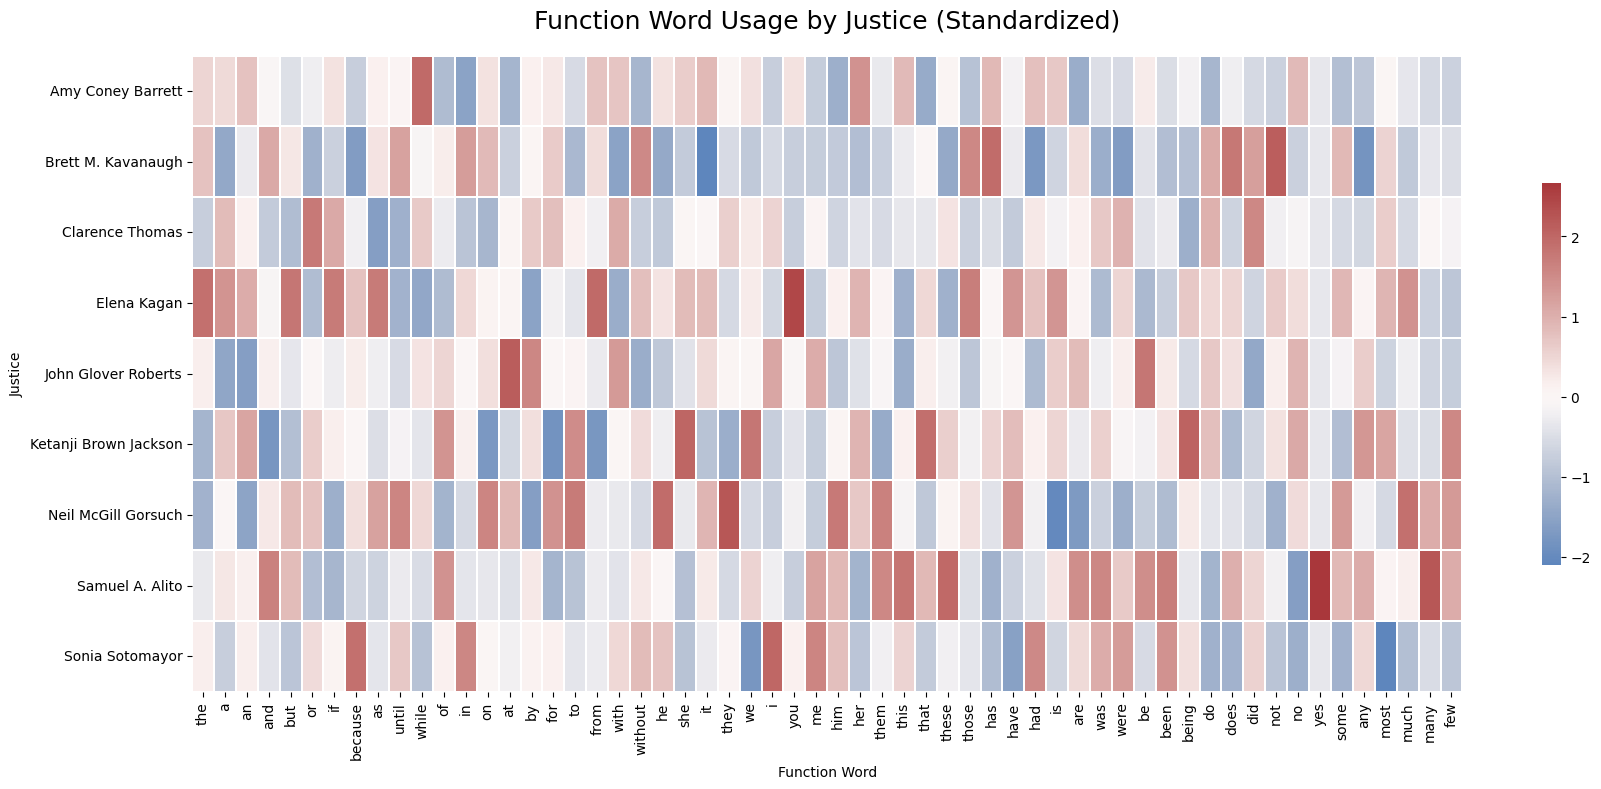

In [ ]:
fw_cols = [c for c in exploded_df.columns if c.startswith("fw_")]
author_fw_means = exploded_df.groupby("author")[fw_cols].mean()
author_fw_means_z = (author_fw_means - author_fw_means.mean()) / author_fw_means.std()
author_fw_means_z.columns = [col.replace("fw_", "") for col in author_fw_means_z.columns]

verbose = True

if not verbose:
  author_fw_means_z = author_fw_means_z[["at", "he", "she", "it", "we", "i", "you", "these", "yes", "most", "many"]]

plt.figure(figsize=(18, 8))
sns.heatmap(
    author_fw_means_z,
    cmap="vlag",
    center=0,
    linewidths=0.3,
    cbar_kws={"shrink": 0.6}
)
plt.title("Function Word Usage by Justice (Standardized)", fontsize=18, pad=20)
plt.xlabel("Function Word")
plt.ylabel("Justice")
plt.tight_layout()
plt.show()

As shown in the visualization above, function word usage graph above reveals substantially different patterns across justices, thus suggesting that it may be a useful feature in our final model.

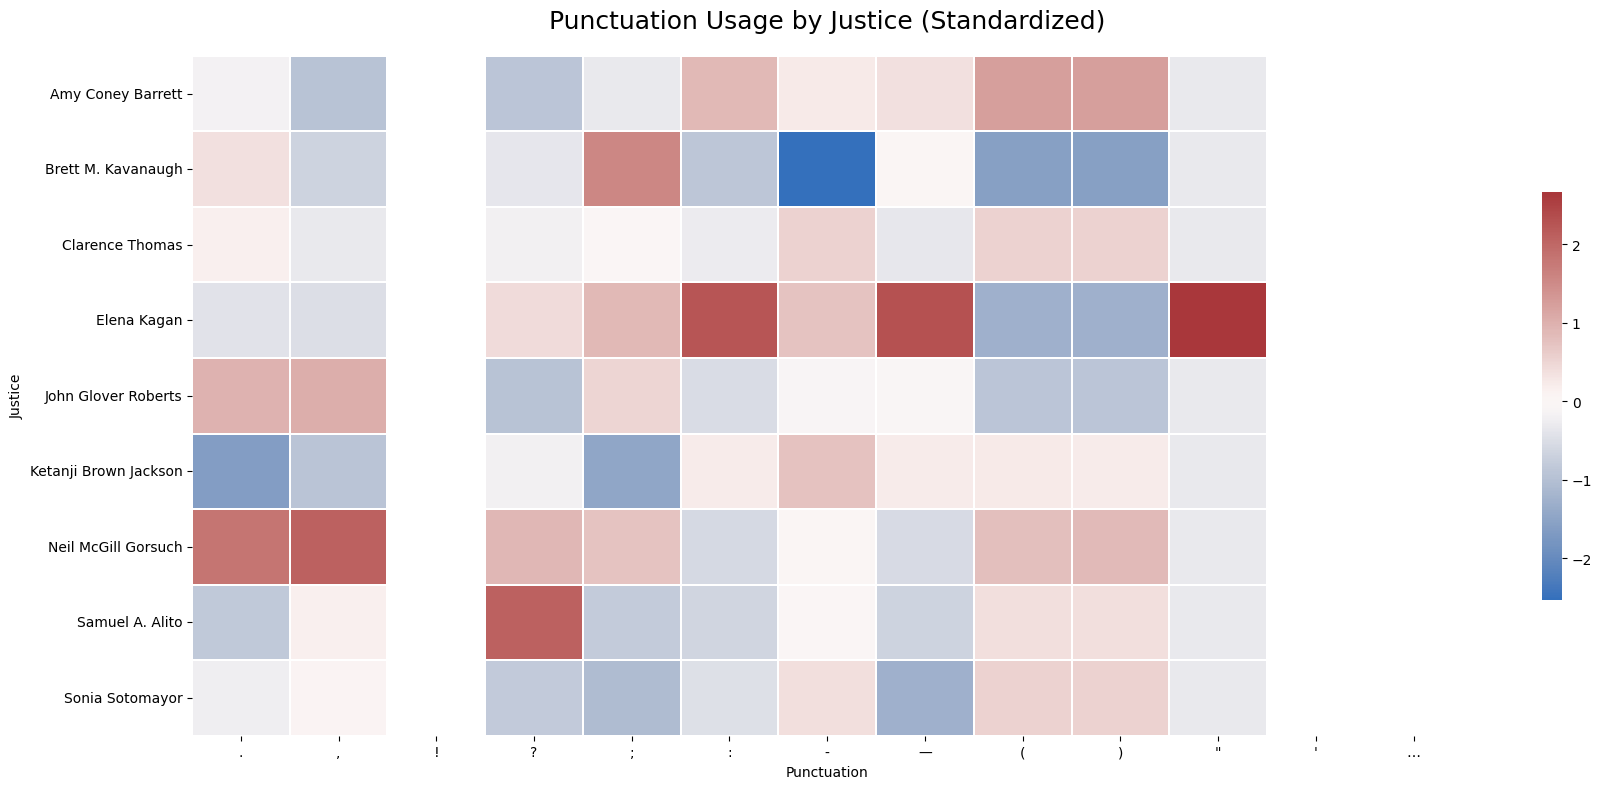

In [ ]:
punc_cols = [c for c in exploded_df.columns if c.startswith("punc")]
author_punc_means = exploded_df.groupby("author")[punc_cols].mean()
author_punc_means_z = (author_punc_means - author_punc_means.mean()) / author_punc_means.std()
author_punc_means_z.columns = [col.replace("punc_", "") for col in author_punc_means_z.columns]
plt.figure(figsize=(18, 8))
sns.heatmap(
    author_punc_means_z,
    cmap="vlag",
    center=0,
    linewidths=0.3,
    cbar_kws={"shrink": 0.6}
)
plt.title("Punctuation Usage by Justice (Standardized)", fontsize=18, pad=20)
plt.xlabel("Punctuation")
plt.ylabel("Justice")
plt.tight_layout()
plt.show()

As shown in the above figure, there does seem to be some pretty significant patterns in punctuation use by justice. Elena Kagan is the greatest user of colons, em–dash, and quotation marks, perhaps showcasing a more complex style of prose. This is well-noted online. Kavanaugh almost never uses hyphens in his opinion. This is because he turned off auto-hypothenation in his writing, according to one Supreme Court journalist. Alito uses question marks at a far higher rate. Punctuation therefore greatly differs across justice and likely offers some good predictive value.

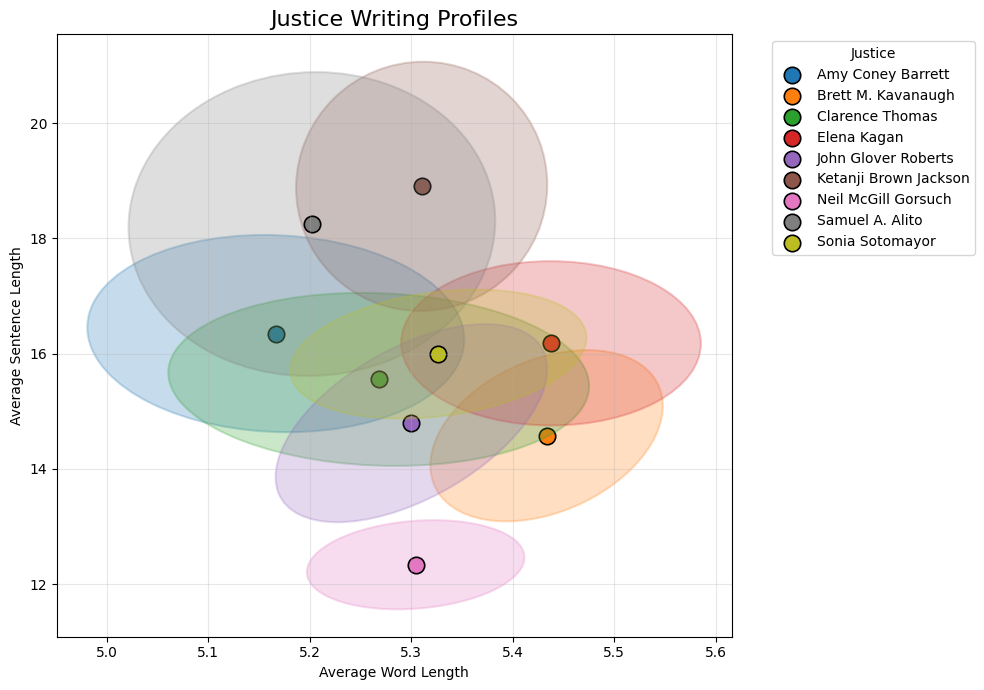

In [ ]:
plt.figure(figsize=(10,7))
ax = plt.gca()

author_groups = exploded_df.groupby("author")

colors = sns.color_palette("tab10", len(author_groups))

for (author, group), color in zip(author_groups, colors):
    m = group[["avg_word_length", "avg_sentence_length"]].mean()
    cov = group[["avg_word_length", "avg_sentence_length"]].cov()

    vals, vecs = np.linalg.eigh(cov.values)

    width, height = 1.0 * np.sqrt(vals)

    angle = np.degrees(np.arctan2(*vecs[:, 0][::-1]))

    ellipse = Ellipse(
        xy=(m["avg_word_length"], m["avg_sentence_length"]),
        width=width,
        height=height,
        angle=angle,
        alpha=0.25,
        edgecolor=color,
        facecolor=color,
        linewidth=1.5
    )
    ax.add_patch(ellipse)

    ax.scatter(
        m["avg_word_length"],
        m["avg_sentence_length"],
        s=140,
        color=color,
        edgecolor="black",
        linewidth=1.2,
        label=author
    )

ax.grid(alpha=0.3)

plt.xlabel("Average Word Length")
plt.ylabel("Average Sentence Length")
plt.title("Justice Writing Profiles", fontsize=16)

plt.legend(title="Justice", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

There are a few patterns from the above visualization. Some justices are more verbose than others (e.g., Kagan and Kavanaugh) whereas others prefer choppier sentences, like Gorsuch. The circles highlight the variability, and the opinions seem to have the greatest within-justice variability across word length, whereas the greater source of across-justice variability appears to be sentence length. Overall, there doesn’t appear to be a clear relationship between average sentence length and average word length, but this does not discount either as a predictor (and speaks to perhaps less collinearity than originally thought between these two features).

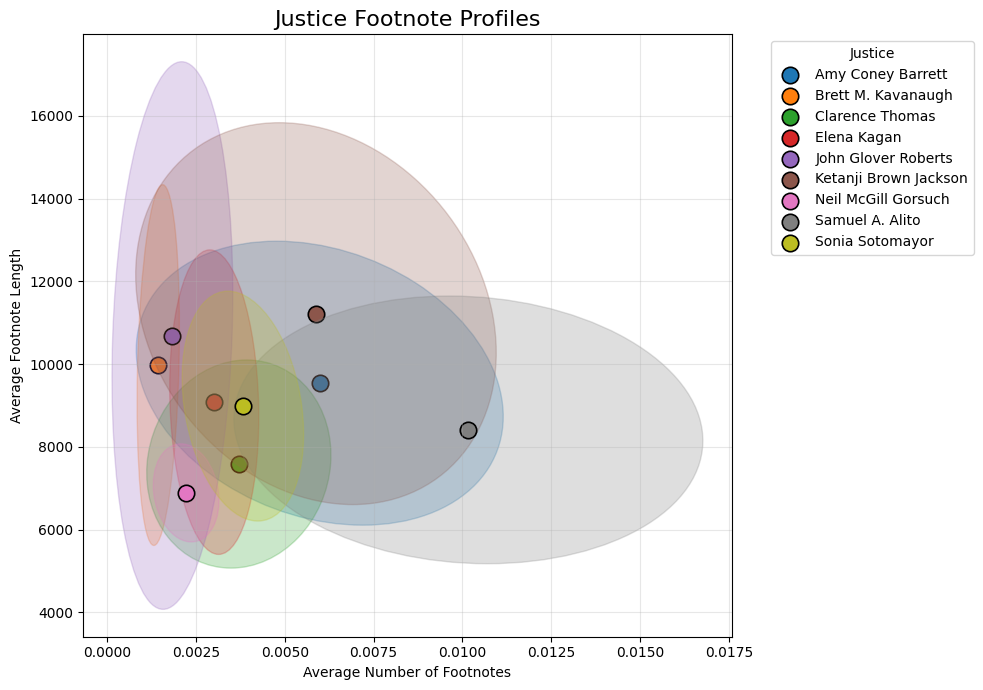

In [ ]:
plt.figure(figsize=(10,7))
ax = plt.gca()


for (author, group), color in zip(author_groups, colors):
    m = group[["num_footnotes", "avg_footnote_length"]].mean()
    cov = group[["num_footnotes", "avg_footnote_length"]].cov()

    vals, vecs = np.linalg.eigh(cov.values)

    width, height = 1.0 * np.sqrt(vals)
    angle = np.degrees(np.arctan2(*vecs[:,0][::-1]))

    ellipse = Ellipse(
        xy=(m["num_footnotes"], m["avg_footnote_length"]),
        width=width,
        height=height,
        angle=angle,
        edgecolor=color,
        facecolor=color,
        alpha=0.25
    )
    ax.add_patch(ellipse)

    ax.scatter(
        m["num_footnotes"], m["avg_footnote_length"],
        color=color, s=140, edgecolor="black", linewidth=1.2,
        label=author
    )

ax.grid(alpha=0.3)
plt.xlabel("Average Number of Footnotes")
plt.ylabel("Average Footnote Length")
plt.title("Justice Footnote Profiles", fontsize=16)
plt.legend(title="Justice", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

Some interesting observations emerge from the above plot of average number of footnotes and footnote length. Alito stands out as having the most footnotes by far, a well-noted characteristic of the Justice. The other justices seem to cluster around similar areas with presumably less predictive power, but there are still differences in both length and frequency between Gorsuch and Jackson, who tends to be a more frequent user of footnotes and is far more verbose, for instance.


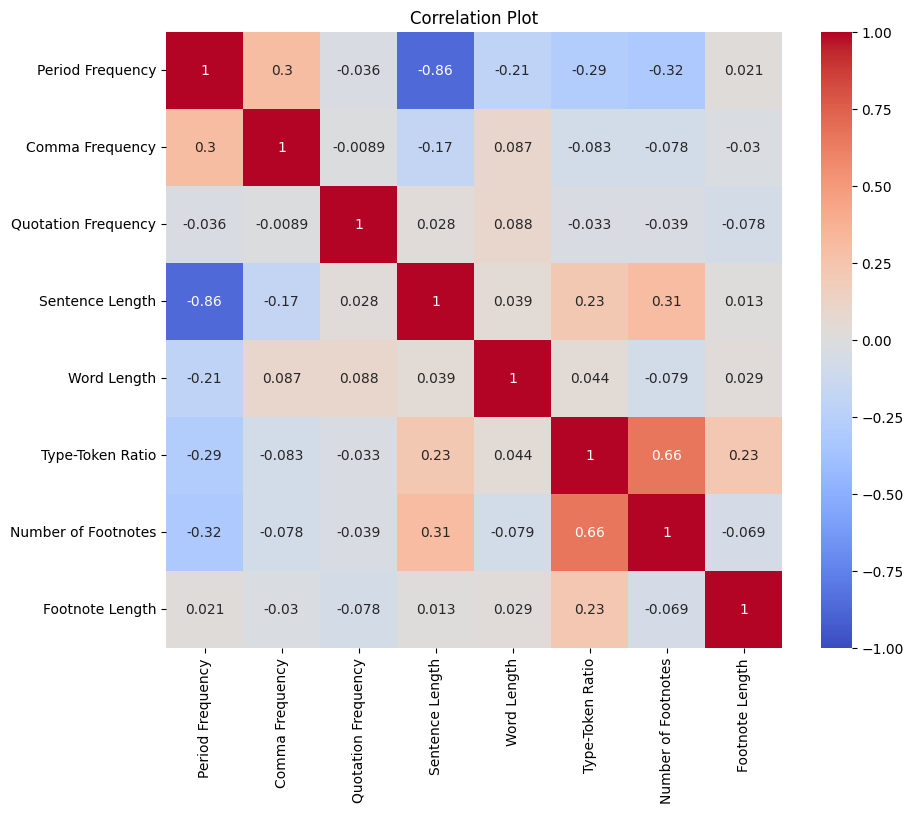

In [ ]:
corr = exploded_df[["punc_.", "punc_,", 'punc_"', "avg_sentence_length", "avg_word_length", "type_token_ratio", "num_footnotes", "avg_footnote_length"]].corr()

corr = corr.rename(index={
    "punc_.": "Period Frequency",
    "punc_,": "Comma Frequency",
    'punc_"': "Quotation Frequency",
    "avg_sentence_length": "Sentence Length",
    "avg_word_length": "Word Length",
    "type_token_ratio": "Type-Token Ratio",
    "num_footnotes": "Number of Footnotes",
    "avg_footnote_length": "Footnote Length"
}).rename(columns={
    "punc_.": "Period Frequency",
    "punc_,": "Comma Frequency",
    'punc_"': "Quotation Frequency",
    "avg_sentence_length": "Sentence Length",
    "avg_word_length": "Word Length",
    "type_token_ratio": "Type-Token Ratio",
    "num_footnotes": "Number of Footnotes",
    "avg_footnote_length": "Footnote Length"
})

plt.figure(figsize=(10,8))
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    vmin=-1, vmax=1,
    square=True
)
plt.title("Correlation Plot")
plt.show()

As we can see from the visualizations above, there are surprising relationships in the variables, even while analyzing our metrics by hand.  Our results from this EDA confirm that our method is capable of identifying distinctions between different justices.

We are aware of potential issues with multi-collinearity.  In particular, measures of sentence length and period frequency are highly correlated, as are type-token ratio and the number of footnotes (the former makes intuitive sense, the latter… somewhat less so).  At this stage, we aren’t particularly worried about multi-collinearity—we hoped to create as many stylistic descriptors as possible, so that we might select among them.  However, we recognize that a careful feature selection process will be necessary to ensure the reliability of our model.


# **Part 6: Model Creation**

### **Naive Model: Majority Class**

In [ ]:
majority_class = y_train.value_counts().idxmax()

y_pred_majority = np.full_like(y_test, majority_class)

majority_macro_f1 = f1_score(y_test, y_pred_majority, average='macro')

print("Majority Class:", majority_class)
print("Macro F1 Score (majority baseline):", round(majority_macro_f1, 3))

Majority Class: Clarence Thomas
Macro F1 Score (majority baseline): 0.026


### **Baseline Model: Logistic Regression**

We chose to use a logistic regression as our baseline model because it provides an simple yet useful and interpretable way of classifying each written opinion with all of our predictors. In later sections, we discuss alternative classification methods, such as Random Forests.

$$
\ln\!\left(\frac{\Pr(Y_i = 1)}{\Pr(Y_i = 0)}\right)
= \beta_0
+ \beta_{\text{sent}}\,\text{SentLen}_i
+ \beta_{\text{word}}\,\text{WordLen}_i
+ \beta_{\text{ttr}}\,\text{TTR}_i
+ \beta_{\text{fn}}\,\text{FootnoteNum}_i
+ \beta_{\text{fnlen}}\,\text{FootnoteLen}_i
+ \sum_{j=0}^{J_{\text{fw}}} \beta^{\text{fw}}_j\,\text{FW}_{ij}
+ \sum_{k=0}^{K_{\text{punc}}} \beta^{\text{punc}}_k\,\text{PUNC}_{ik}
+ \sum_{\ell=0}^{L_{\text{pos}}} \beta^{\text{pos}}_\ell\,\text{POS}_{i\ell}
$$

$$
Y_i =
\begin{cases}
1, & \text{if case } i \text{ is written by the target justice (e.g., Kagan)},\\[6pt]
0, & \text{otherwise}.
\end{cases}
$$

$$
\begin{aligned}
i &= 1,\ldots,N &&\text{number of cases},\\
j &= 0,\ldots,J_{\text{fw}} &&\text{function words},\\
k &= 0,\ldots,K_{\text{punc}} &&\text{punctuation marks},\\
\ell &= 0,\ldots,L_{\text{pos}} &&\text{POS bigrams}.
\end{aligned}
$$


In [ ]:
C_grid = np.logspace(-4, 3, 20)

param_grid = {"log__C": C_grid}

clf = Pipeline([
    ('scaler', StandardScaler()),
    ('log', LogisticRegression(
        penalty="l2",
        solver="lbfgs",
        max_iter=2000
    ))])

log = GridSearchCV(
    clf,
    param_grid,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1
)

log.fit(X_train, y_train)

print("Best parameters:", log.best_params_)
print(f"Best f1_score: {log.best_score_:.3f}")

Best parameters: {'log__C': np.float64(2.6366508987303554)}
Best f1_score: 0.353


Preliminary results from our simple logistic classifier give us a mean macro F1 score of 35%.  Though this is worse than a coin flip, it is much better than random chance—since we select one of the nine possible justices (naive probability: 11%).  Still, we’d like better.  In the next section, we apply progressively more advanced models in hopes of having more accurate classifications.

### **Advanced Model 1: One Decision Tree**

In [ ]:
param_grid_dt = {
    "max_depth": [5, 10, 20, 30, 40, 50, None],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 4, 8],
    "criterion": ["gini", "entropy"]}

clf = DecisionTreeClassifier(
    class_weight="balanced",
    random_state=109)

# Use GridSearch for hypterparameter tuning
dt = GridSearchCV(
    estimator=clf,
    param_grid=param_grid_dt,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1)

dt.fit(X_train, y_train)

print("Best parameters:", dt.best_params_)
print(f"Best CV F1 Score: {dt.best_score_:.3f}")

Best parameters: {'criterion': 'gini', 'max_depth': 20, 'min_samples_leaf': 4, 'min_samples_split': 10}
Best CV F1 Score: 0.377


A decision tree model improves slighly, but not significantly, upon the logistic regression baseline. We can still do better with an ensemble model. Moreover, decision trees that are deep tend to have higher variance and overfit more quickly. Using a **Random Forest** model, as we do below, can help alleivate the issues caused by high variance.

### **Advanced Model 2: Random Forest**

For our random forest model, we use RandomizedSearchCV to find the optimal hyperparameters. This is because the random forest model is training many trees, and therefore takes longer than our simple decision tree model. Using GridSearchCV results in very long training times.

In [ ]:
param_grid_refined = {
    "n_estimators": [150, 200, 250, 300, 350],
    "max_depth": [12, 15, 18, 20],
    "max_features": [0.03, 0.05, 0.07],
    "min_samples_split": [2, 5, 10, 15],
    "min_samples_leaf": [4, 6, 8, 10],
}


clf = RandomForestClassifier(
    class_weight="balanced",
    random_state=109
)

rf = RandomizedSearchCV(
    estimator=clf,
    param_distributions=param_grid_refined,
    n_iter=25,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1,
    random_state=42,
)

rf.fit(X_train, y_train)

print("Best Parameters:", rf.best_params_)
print(f"Best CV F1 Score: {rf.best_score_:.3f}")

Best Parameters: {'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 6, 'max_features': 0.07, 'max_depth': 20}
Best CV F1 Score: 0.538


This is a very promising result from the random forest model. However, we still may be able to increase performance via boosting, which we explore below.

### **Advanced Model 3: AdaBoost**

We decide to examine the performance of AdaBoost to see if we can improve upon our random forest model. This is because AdaBoost is specialized toward classification problems compared to other boosting methods which are more polymorphic in regard to the types of problems they're applied to.

In [ ]:
clf = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(),
    random_state=109
)

param_grid_ada = {
    "n_estimators": [50, 100, 200, 300, 400],
    "learning_rate": [0.01, 0.05, 0.1, 0.5, 1.0],
    "estimator__max_depth": [1, 2, 3]
}

ada = RandomizedSearchCV(
    estimator=clf,
    param_distributions=param_grid_ada,
    n_iter=20,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1,
    random_state=42
)

ada.fit(X_train, y_train)

print("Best Parameters:", ada.best_params_)
print(f"Best CV F1 Score: {ada.best_score_:.3f}")

Best Parameters: {'n_estimators': 100, 'learning_rate': 0.05, 'estimator__max_depth': 3}
Best CV F1 Score: 0.449


AdaBoost performs significantly worse than random forest. We'll examine the consequences of this in our model selection part below.

# **Part 7: Model Selection**

In [ ]:
results_table = pd.DataFrame([
    {
        "Model": "Naive Majority Class",
        "Best Params": f"Majority class={majority_class}",
        "Macro F1 Score": round(majority_macro_f1, 3)
    },
    {
        "Model": "Logistic Regression (L2)",
        "Best Params": f"C={log.best_params_['log__C']:.4f}",
        "Macro F1 Score": round(log.best_score_, 3)
    },
    {
        "Model": "Decision Tree",
        "Best Params": str(dt.best_params_),
        "Macro F1 Score": round(dt.best_score_, 3)
    },
    {
        "Model": "Random Forest",
        "Best Params": str(rf.best_params_),
        "Macro F1 Score": round(rf.best_score_, 3)
    },
    {
        "Model": "AdaBoost",
        "Best Params": str(ada.best_params_),
        "Macro F1 Score": round(ada.best_score_, 3)
    },
], columns=["Model", "Best Params", "Macro F1 Score"])

results_table

,Model,Best Params,Macro F1 Score
0,Naive Majority Class,Majority class=Clarence Thomas,0.026
1,Logistic Regression (L2),C=2.6367,0.353
2,Decision Tree,"{'criterion': 'gini', 'max_depth': 20, 'min_sa...",0.377
3,Random Forest,"{'n_estimators': 300, 'min_samples_split': 5, ...",0.538
4,AdaBoost,"{'n_estimators': 100, 'learning_rate': 0.05, '...",0.449


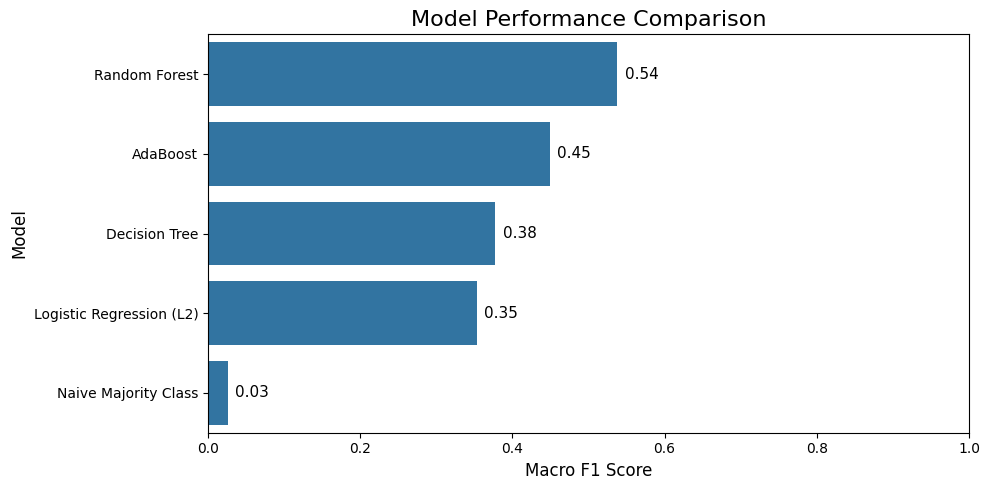

In [ ]:
results_sorted = results_table.sort_values("Macro F1 Score", ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=results_sorted,
    x="Macro F1 Score",
    y="Model"
)

plt.xlabel("Macro F1 Score", fontsize=12)
plt.ylabel("Model", fontsize=12)
plt.title("Model Performance Comparison", fontsize=16)
plt.xlim(0, 1)

for i, v in enumerate(results_sorted["Macro F1 Score"]):
    plt.text(v + 0.01, i, f"{v:.2f}", va="center", fontsize=11)

plt.tight_layout()
plt.show()

Since the Random Forest model performs the best in cross validation on Macro F1, we select it as our final model. Random Forest models are able to describe more complex decision boundaries than decision trees or logistic regressions. It is not a surprise to see it perform so well.

We use Macro F1 as our metric of choice because our class imbalance makes accuracy too optimistic of a measure.

# **Part 8: Model Performance**

After retraining our best models in each category on all the training data, we apply them to our test split. This is data that the model has never seen before, so that we avoid potential issues with data leakage.

In [ ]:
rf_pred = rf.predict(X_test)

In [ ]:
test_results_table = pd.DataFrame([
    {
        "Model": "Random Forest",
        "Test F1 Score": round(f1_score(y_test, rf_pred, average='macro'), 3),
        "Test Accuracy": round(accuracy_score(y_test, rf_pred), 3),
        "Test Precision": round(precision_score(y_test, rf_pred, average='macro', zero_division=0.0), 3),
        "Test Recall": round(recall_score(y_test, rf_pred, average='macro'), 3)
    },
], columns=["Model", "Test F1 Score", "Test Accuracy", "Test Precision", "Test Recall"])

test_results_table

,Model,Test F1 Score,Test Accuracy,Test Precision,Test Recall
0,Random Forest,0.569,0.63,0.58,0.581


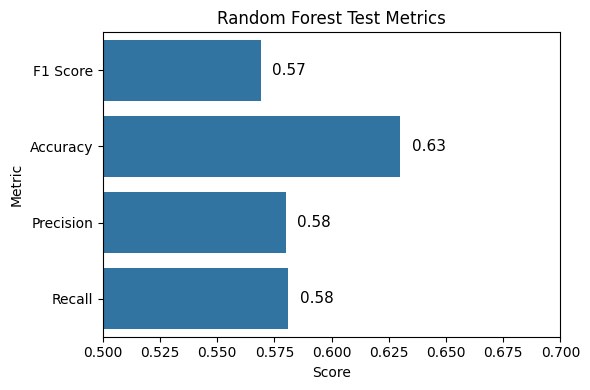

In [ ]:
plt.figure(figsize=(6, 4))

metrics = ["F1 Score", "Accuracy", "Precision", "Recall"]
values = test_results_table.iloc[0, 1:].values

plot_df = pd.DataFrame({
    "Metric": metrics,
    "Score": values
})

ax = sns.barplot(
    data=plot_df,
    x="Score",
    y="Metric",
    orient="h"
)

ax.set_xlim(0.5, 0.7)
ax.set_title("Random Forest Test Metrics")
ax.set_xlabel("Score")

# Add value labels
for i, v in enumerate(values):
    ax.text(v + 0.005, i, f"{v:.2f}", va="center", fontsize=11)

plt.tight_layout()
plt.show()

As we can see above, our Random Forest model exhibits a similar F1 score and an even higher accuracy on our test set as it did during cross validation. Our RF model is 4.5x more accurate than just predicting the majority class (Clarence Thomas) and offers an even greater improvement in accuracy compared to both our decision tree and logistic regression model.

### **Feature Importance**

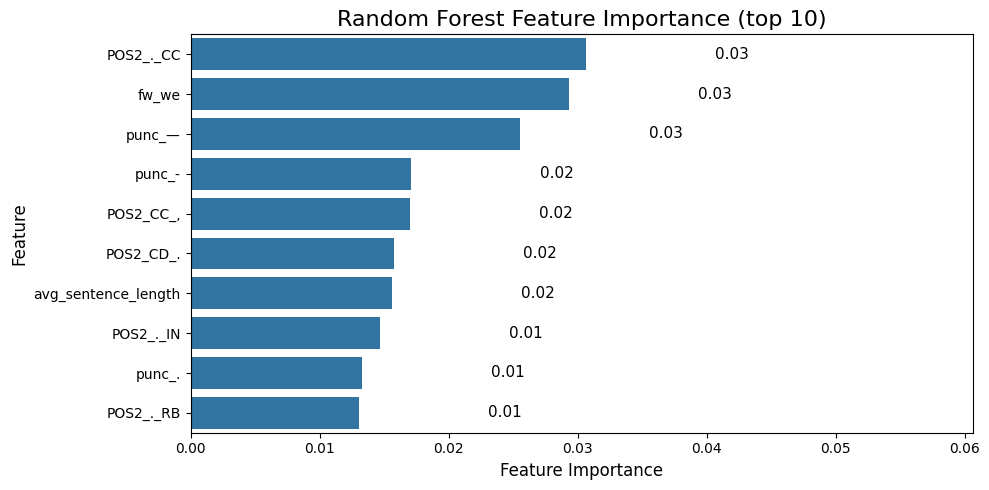

In [ ]:
importance = pd.DataFrame({"Feature": X_train.columns, "Importance": rf.best_estimator_.feature_importances_})
importance = importance.sort_values(by='Importance', ascending=False)[0:10]

plt.figure(figsize=(10, 5))
sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)

plt.xlabel("Feature Importance", fontsize=12)
plt.ylabel("Feature", fontsize=12)
plt.title("Random Forest Feature Importance (top 10)", fontsize=16)
plt.xlim(0, importance['Importance'].iloc[0] + 0.03)

for i, v in enumerate(importance["Importance"]):
    plt.text(v + 0.01, i, f"{v:.2f}", va="center", fontsize=11)

plt.tight_layout()
plt.show()

Punctuation, function words, and POS n-grams dominated our feature importance graph, showing that these extracted features are the strongest predictors of authorship for Supreme Court majority opinions. The most important feature identified by the model was ```._CC```, which represents a period followed by a coordinating conjunction.

### **Confusion Matrix**

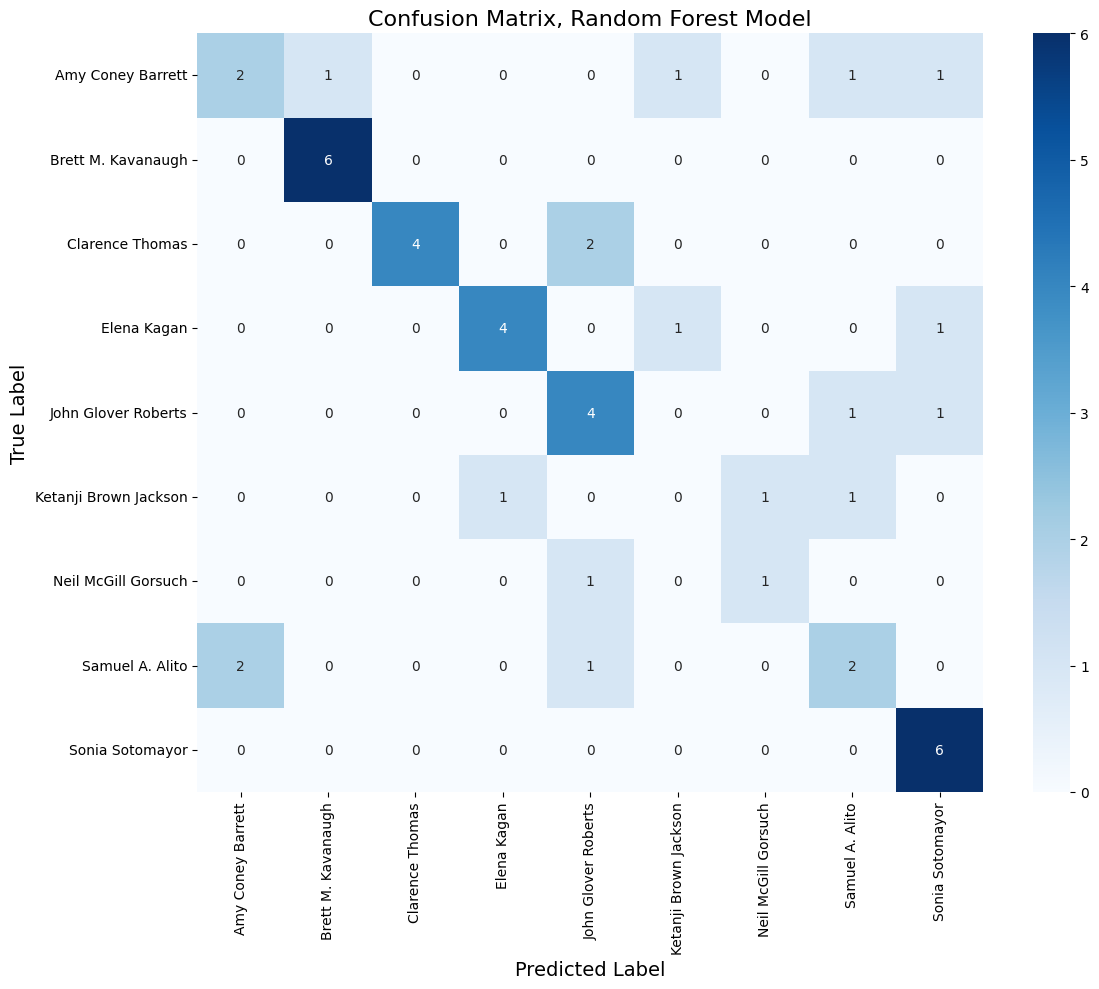

In [ ]:
cm = confusion_matrix(y_test, rf_pred, labels=rf.classes_)

plt.figure(figsize=(12, 10))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=rf.classes_,
    yticklabels=rf.classes_
)

plt.xlabel("Predicted Label", fontsize=14)
plt.ylabel("True Label", fontsize=14)
plt.title("Confusion Matrix, Random Forest Model", fontsize=16)
plt.tight_layout()
plt.show()

The confusion matrix highlights where our model is most likely to make mistakes and how often the model correctly / incorrectly predicted each justice. Concerningly, our model never correctly predicted Kentaji Brown Jackson, which may be a consequence of our smaller dataset due to the limited number of majority opinions between 2021-2025. If we were to look back further in time, however, we may exacerbate our class imbalance.

Besides for that observation, we can note that our model is most likely to confuse Alito with Barrett and Thomas with Roberts. It is interesting to note these occur on ideological lines (all conservative justices), though no substantive conclusion can be drawn from this without further analysis.

# **Part 9: Application to a *Per Curiam* Case**

The case we choose to examine is the infamous *Trump v. Anderson*, where SCOTUS, in an unsigned per curiam opinion, held that states lack the constitutional authority to disqualify federal candidates under Section 3 of the Fourteenth Amendment, reversing Colorado’s attempt to bar Donald Trump from its 2024 presidential primary ballot.

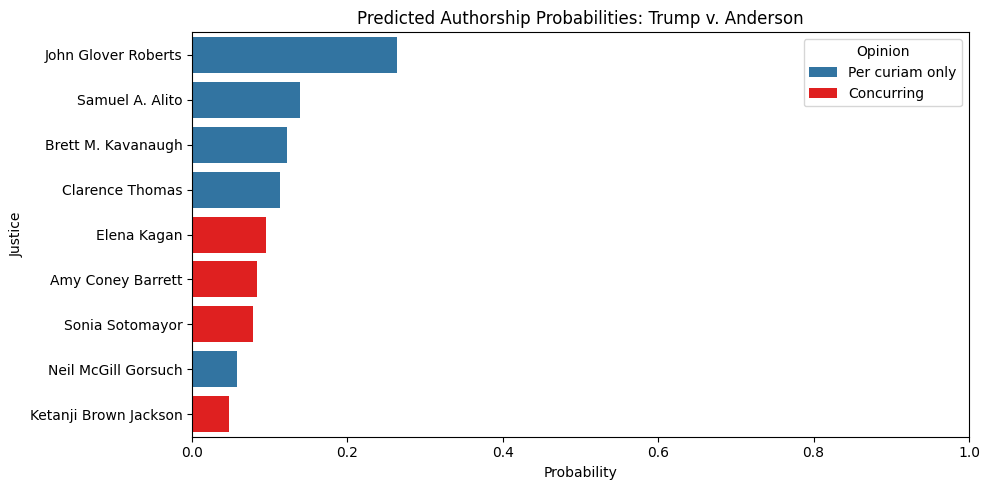

In [ ]:
trump = per_curiam[per_curiam["case_name"] == "Trump v. Anderson"]
cols = rf.best_estimator_.feature_names_in_
X_trump = trump[cols]

probs = rf.best_estimator_.predict_proba(X_trump)[0]
classes = rf.best_estimator_.classes_

trump_probs = (
    pd.DataFrame({"Justice": classes, "Probability": probs})
      .sort_values("Probability", ascending=False)
      .reset_index(drop=True)
)

concurring = {
    "Amy Coney Barrett",
    "Sonia Sotomayor",
    "Elena Kagan",
    "Ketanji Brown Jackson"
}

trump_probs["Opinion"] = np.where(
    trump_probs["Justice"].isin(concurring),
    "Concurring",
    "Per curiam only"
)

plt.figure(figsize=(10,5))
sns.barplot(
    data=trump_probs,
    x="Probability",
    y="Justice",
    hue="Opinion",
    palette={"Per curiam only": "C0", "Concurring": "red"}
)

plt.xlim(0, 1)
plt.title("Predicted Authorship Probabilities: Trump v. Anderson")
plt.tight_layout()
plt.show()

While we do not definitively know who wrote the opinion since it is unsigned by nature, we have some information to evaluate our model in the form of concurring opinions. Concurring opinions are signed, and it is unlikely a justice would both be the author of the opinion of the majority and their own concurrence. It is a good sign for our model that four of the bottom five in predicted probability of writing the *Trump v. Anderson* per curiam opinion also wrote concurrences, making them logically unlikely to be the author.